In medical image classification, recall is especially important because false negatives may represent missed PCOS cases.

Therefore, threshold analysis was performed instead of relying only on the default threshold of 0.5.

Different thresholds were evaluated to improve the balance between precision and recall. The optimal threshold was selected based on F1-score and recall performance.

# 04. Model Evaluation and Threshold Analysis

This notebook evaluates the final selected CNN model on the untouched test set.

The selected model is Version 1 because it achieved more stable validation performance compared with Version 2.  
The evaluation includes:
- test loss and accuracy
- precision, recall, F1-score, and AUC
- confusion matrix
- ROC curve
- threshold analysis to study the precision-recall trade-off

Threshold analysis is important in medical image classification because false negatives may represent missed PCOS cases.

## 1. Load the Test Set and the Final CNN Model

The test set is loaded only at the final evaluation stage.  
The best CNN model from Version 1 is used because it achieved better validation stability.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

## 2. Fix Image Paths

The CSV file contains image paths saved during earlier preprocessing.  
Since the notebook may run from a different folder, the image paths are rebuilt using the project directory, class label, and image filename.

In [2]:
PROJECT_DIR = Path(r"C:\Users\MHawa\OneDrive\Desktop\DL project")

TEST_CSV = PROJECT_DIR / "data" / "processed" / "test_df.csv"
MODEL_PATH = PROJECT_DIR / "models" / "best_pcos_cnn_model.keras"
FIGURES_DIR = PROJECT_DIR / "figures"

FIGURES_DIR.mkdir(exist_ok=True)

test_df = pd.read_csv(TEST_CSV)

model = tf.keras.models.load_model(MODEL_PATH)

print("Test dataframe shape:", test_df.shape)
test_df.head()

Test dataframe shape: (1768, 5)


,image_path,label,width,height,label_encoded
0,data\PCOS\PCOS\noninfected\Image_SetB994.jpg,noninfected,984,848,0
1,data\PCOS\PCOS\noninfected\Image_SetA800.jpg,noninfected,315,160,0
2,data\PCOS\PCOS\noninfected\Image_resize_671 (...,noninfected,984,848,0
3,data\PCOS\PCOS\infected\Image_SETA_716.jpg,infected,300,300,1
4,data\PCOS\PCOS\infected\Image_resize_343.jpg,infected,171,171,1


In [3]:
DATA_ROOT = PROJECT_DIR / "data" / "PCOS" / "PCOS"

test_df["image_name"] = test_df["image_path"].apply(lambda x: Path(x).name)

test_df["image_path"] = test_df.apply(
    lambda row: str(DATA_ROOT / row["label"] / row["image_name"]),
    axis=1
)

print(test_df["image_path"].head())
print("Existing files:", test_df["image_path"].apply(os.path.exists).sum())
print("Total files:", len(test_df))

0    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
1    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
2    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
3    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
4    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
Name: image_path, dtype: str
Existing files: 1768
Total files: 1768


## 3. Create the Test Image Generator

Only normalization is applied to the test set.  
No augmentation is used during testing because the test set must represent real unseen images.

In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_df["label_encoded"] = test_df["label_encoded"].astype(str)

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="label_encoded",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 1768 validated image filenames belonging to 2 classes.


## 4. Evaluate the Model on the Test Set

The final model is evaluated on the untouched test set.  
This provides an unbiased estimate of model performance.

In [5]:
test_results = model.evaluate(test_generator, verbose=1)

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 27s 459ms/step - accuracy: 0.8920 - auc: 0.9481 - loss: 0.7914 - precision: 1.0000 - recall: 0.8124
loss: 0.7914
compile_metrics: 0.8920


## 6. Evaluation at the Default Threshold 0.50

The default threshold for binary classification is 0.50.  
If the predicted probability is greater than or equal to 0.50, the image is classified as infected.

In [6]:
test_generator.reset()

y_prob = model.predict(test_generator, verbose=1).ravel()
y_true = test_generator.classes

print("Number of true labels:", len(y_true))
print("Number of predictions:", len(y_prob))

56/56 ━━━━━━━━━━━━━━━━━━━━ 24s 424ms/step
Number of true labels: 1768
Number of predictions: 1768


## 7. Confusion Matrix at Threshold 0.50

The confusion matrix shows the number of correct and incorrect predictions for each class.

In medical diagnosis, false negatives are especially important because they represent infected cases that were missed by the model.

In [7]:
default_threshold = 0.50
y_pred_05 = (y_prob >= default_threshold).astype(int)

class_names = ["noninfected", "infected"]

accuracy_05 = accuracy_score(y_true, y_pred_05)
precision_05 = precision_score(y_true, y_pred_05)
recall_05 = recall_score(y_true, y_pred_05)
f1_05 = f1_score(y_true, y_pred_05)
auc_05 = roc_auc_score(y_true, y_prob)

metrics_05 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUC"],
    "Score": [accuracy_05, precision_05, recall_05, f1_05, auc_05]
})

metrics_05.to_csv(FIGURES_DIR / "metrics_threshold_0.5.csv", index=False)
print(metrics_05)

      Metric     Score
0   Accuracy  0.891968
1  Precision  1.000000
2     Recall  0.812377
3   F1-score  0.896477
4        AUC  0.978043


In [8]:
print(classification_report(
    y_true,
    y_pred_05,
    target_names=class_names
))

              precision    recall  f1-score   support

 noninfected       0.80      1.00      0.89       750
    infected       1.00      0.81      0.90      1018

    accuracy                           0.89      1768
   macro avg       0.90      0.91      0.89      1768
weighted avg       0.91      0.89      0.89      1768



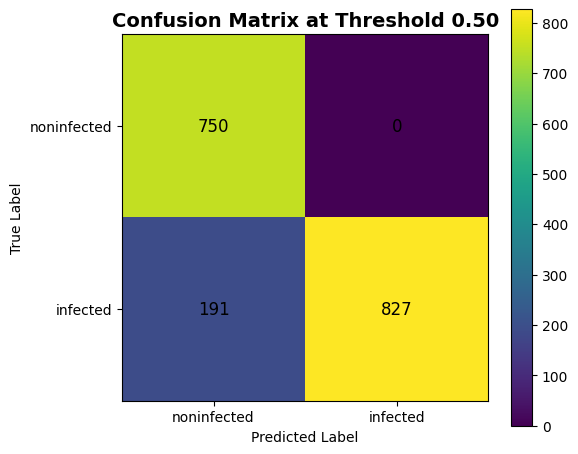

array([[750,   0],
       [191, 827]])

In [9]:
cm_05 = confusion_matrix(y_true, y_pred_05)

plt.figure(figsize=(6, 5))
plt.imshow(cm_05)
plt.title("Confusion Matrix at Threshold 0.50", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_05[i, j], ha="center", va="center", fontsize=12)

plt.colorbar()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_threshold_050.png", dpi=300)
plt.show()

cm_05

## 8. ROC Curve

The ROC curve evaluates how well the model separates infected and noninfected classes across different thresholds.  
A higher AUC indicates better class separation.

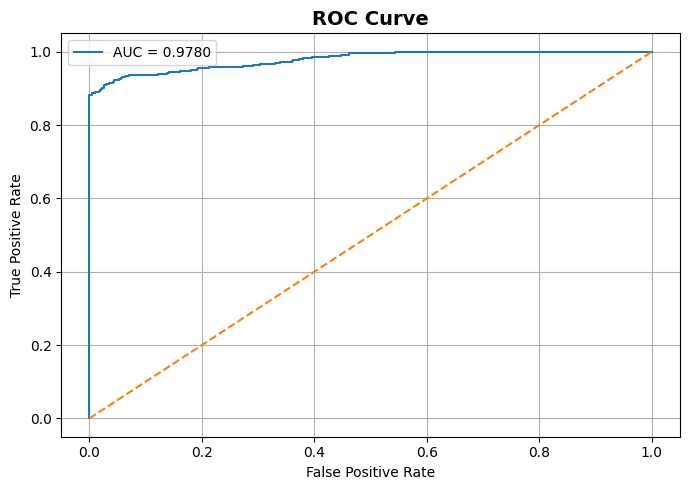

In [10]:
fpr, tpr, roc_thresholds = roc_curve(y_true, y_prob)
auc_score = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_curve.png", dpi=300)
plt.show()

## 9. Threshold Analysis

The default threshold of 0.50 may not always be optimal, especially in medical classification.

Because missing an infected PCOS case can be more serious than a false alarm, recall is very important.  
Therefore, different thresholds are tested to study the trade-off between precision, recall, and F1-score.

This threshold adjustment is applied only during evaluation. It does not change the trained CNN model.

In [11]:
threshold_values = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in threshold_values:
    y_pred_temp = (y_prob >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": round(threshold, 2),
        "accuracy": accuracy_score(y_true, y_pred_temp),
        "precision": precision_score(y_true, y_pred_temp, zero_division=0),
        "recall": recall_score(y_true, y_pred_temp, zero_division=0),
        "f1_score": f1_score(y_true, y_pred_temp, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,threshold,accuracy,precision,recall,f1_score
0,0.10,0.897624,1.0,0.822200,0.902426
1,0.15,0.896493,1.0,0.820236,0.901241
2,0.20,0.895362,1.0,0.818271,0.900054
3,0.25,0.895362,1.0,0.818271,0.900054
4,0.30,0.895362,1.0,0.818271,0.900054
5,0.35,0.894796,1.0,0.817289,0.899459
6,0.40,0.894231,1.0,0.816306,0.898864
7,0.45,0.893100,1.0,0.814342,0.897672
8,0.50,0.891968,1.0,0.812377,0.896477
9,0.55,0.891968,1.0,0.812377,0.896477


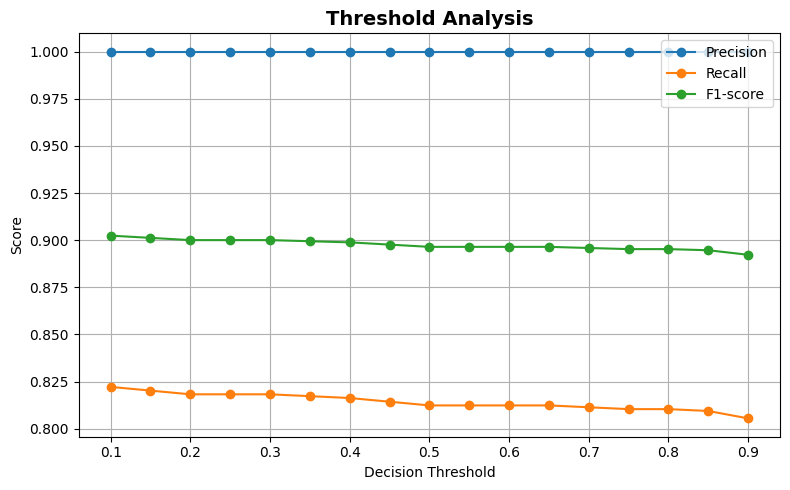

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1_score"], marker="o", label="F1-score")

plt.title("Threshold Analysis", fontsize=14, fontweight="bold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_analysis.png", dpi=300)
plt.show()

## 10. Select the Best Threshold

The best threshold is selected based on F1-score because F1-score balances precision and recall.  
For medical diagnosis, recall is also reviewed carefully to reduce missed infected cases.

In [13]:
best_row = threshold_df.loc[threshold_df["f1_score"].idxmax()]
best_threshold = best_row["threshold"]

print("Best threshold based on F1-score:", best_threshold)
best_row

Best threshold based on F1-score: 0.1


threshold    0.100000
accuracy     0.897624
precision    1.000000
recall       0.822200
f1_score     0.902426
Name: 0, dtype: float64

## 11. Confusion Matrix at the Best Threshold

After selecting the best threshold, the confusion matrix is recalculated to compare it with the default threshold.

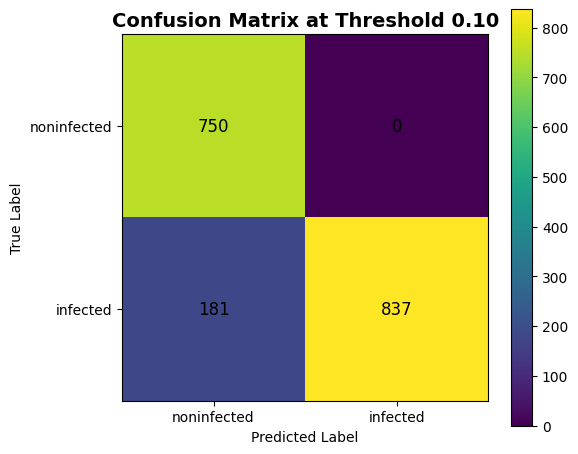

              precision    recall  f1-score   support

 noninfected       0.81      1.00      0.89       750
    infected       1.00      0.82      0.90      1018

    accuracy                           0.90      1768
   macro avg       0.90      0.91      0.90      1768
weighted avg       0.92      0.90      0.90      1768



In [14]:
y_pred_best = (y_prob >= best_threshold).astype(int)

cm_best = confusion_matrix(y_true, y_pred_best)

plt.figure(figsize=(6, 5))
plt.imshow(cm_best)
plt.title(f"Confusion Matrix at Threshold {best_threshold:.2f}", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_best[i, j], ha="center", va="center", fontsize=12)

plt.colorbar()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_best_threshold.png", dpi=300)
plt.show()

print(classification_report(
    y_true,
    y_pred_best,
    target_names=class_names
))

## 12. Save Evaluation Results

The evaluation results are saved for use in the final report and presentation.

In [15]:
metrics_05.to_csv(FIGURES_DIR / "test_metrics_threshold_050.csv", index=False)
threshold_df.to_csv(FIGURES_DIR / "threshold_analysis_results.csv", index=False)

final_predictions = test_df.copy()
final_predictions["true_label"] = y_true
final_predictions["probability_infected"] = y_prob
final_predictions["prediction_threshold_050"] = y_pred_05
final_predictions["prediction_best_threshold"] = y_pred_best

final_predictions.to_csv(FIGURES_DIR / "test_predictions.csv", index=False)

print("Evaluation files saved successfully.")

Evaluation files saved successfully.


## Evaluation Summary

The final CNN model was evaluated on the untouched test set using multiple metrics.

The evaluation included:
- accuracy
- precision
- recall
- F1-score
- AUC
- confusion matrix
- ROC curve
- threshold analysis

Because this is a medical image classification problem, recall is especially important.  
Threshold analysis was used to study whether a lower decision threshold could improve recall and reduce false negatives.

The final threshold decision should be based on the balance between recall, precision, and F1-score.